# Lista 2: Inteligência Artificial (UFAL)
## Questão 14: Grafo de conhecimento sobre arboviroses

**Dupla:**
- Bruno Gomes de Barros Filho, matrícula 21111360
- Antônio Rodrigo Lima de Andrade Tenório, matrícula 23210707

**Disciplina:** ECOM031: Inteligência Artificial
**Professor:** Evandro de Barros Costa
**Período:** 2026.2

O notebook constrói um grafo de conhecimento (KG) pequeno sobre arboviroses no Brasil,
faz inferência dedutiva por materialização (RDFS, OWL 2 RL e duas regras do domínio),
compara consultas SPARQL antes e depois da inferência e treina embeddings TransE para
previsão de links. O código fica nos módulos `kg.py`, `raciocinio.py` e `transe.py`;
aqui ficam a execução e a análise. O ensaio completo está em `docs/q14_knowledge_graphs.md`.

## 0. Imports

In [1]:
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
import pandas as pd
from rdflib import URIRef
from rdflib.namespace import RDF, RDFS

from kg import ARBO, construir_grafo, exportar_cypher, individuos, local, salvar_turtle
from raciocinio import CONSULTAS, consultar, contagem_por_regra, materializar
import transe as te

FIG = Path("figures"); FIG.mkdir(exist_ok=True)
pd.set_option("display.max_colwidth", 120)
# paleta categórica (ordem fixa) e tinta de texto
CORES = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948", "#7a7974"]
TINTA, TINTA2 = "#0b0b0b", "#52514e"
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 150, "axes.spines.top": False,
                     "axes.spines.right": False, "axes.edgecolor": TINTA2, "axes.labelcolor": TINTA,
                     "xtick.color": TINTA2, "ytick.color": TINTA2, "font.size": 10})

## 1. Construção do grafo em RDF

O esquema é leve: 30 classes ligadas por `rdfs:subClassOf`, 20 propriedades de objeto com
domínio, alcance e subpropriedades, e alguns axiomas OWL (inversas, transitivas, uma simétrica
e duas cadeias de propriedades). Os fatos descrevem 7 arboviroses, seus vírus, vetores,
sintomas, complicações, exames, vacinas, medidas de controle e onde ocorrem.

Uma escolha de modelagem importa para o resto: os papéis (`Vetor`, `Arbovirus`, `Arbovirose`)
não são declarados nos dados. Um mosquito não é vetor por ser mosquito; ele é vetor porque
aparece no alcance de `temVetor`. Essa informação só aparece depois da inferência.

In [2]:
g = construir_grafo()
salvar_turtle(g, Path("dados/arboviroses.ttl"))
Path("neo4j/arboviroses.cypher").write_text(exportar_cypher(g), encoding="utf-8")

ents = individuos(g)
esquema = [t for t in g if t[0] not in ents]
fatos_rel = te.triplas_relacionais(g, ents)
print(f"triplas assertadas: {len(g)}")
print(f"  esquema (classes, propriedades, axiomas): {len(esquema)}")
print(f"  rótulos: {len(list(g.triples((None, RDFS.label, None))))}")
print(f"  tipos declarados de indivíduos: {len([1 for s, o in g.subject_objects(RDF.type) if s in ents])}")
print(f"  fatos relacionais entre indivíduos: {len(fatos_rel)} (+1 owl:sameAs)")
print(f"indivíduos: {len(ents)}")

triplas assertadas: 381
  esquema (classes, propriedades, axiomas): 120
  rótulos: 78
  tipos declarados de indivíduos: 26
  fatos relacionais entre indivíduos: 156 (+1 owl:sameAs)
indivíduos: 78


In [3]:
print(Path("dados/arboviroses.ttl").read_text(encoding="utf-8").split("arbo:Dengue ")[1].split("\n\n")[0][:1200])

rdfs:label "Dengue"@pt ;
    arbo:causadaPor arbo:DENV ;
    arbo:diagnosticadaPor arbo:AntigenoNS1,
        arbo:RTqPCR,
        arbo:SorologiaIgM ;
    arbo:diagnosticoDiferencialCom arbo:Chikungunya,
        arbo:Zika ;
    arbo:ocorreEm arbo:Maceio,
        arbo:RegiaoCentroOeste,
        arbo:RegiaoNorte,
        arbo:RegiaoSudeste,
        arbo:RegiaoSul ;
    arbo:podeEvoluirPara arbo:ChoqueHipovolemico,
        arbo:Hemorragia ;
    arbo:temSintoma arbo:Artralgia,
        arbo:Cefaleia,
        arbo:DorRetroOrbital,
        arbo:Exantema,
        arbo:Febre,
        arbo:Mialgia,
        arbo:Nausea,
        arbo:Prurido ;
    arbo:temVacina arbo:VacinaQdenga .


In [4]:
pd.Series(Counter(r for _, r, _ in fatos_rel)).sort_values(ascending=False).rename("fatos").to_frame().T

,temSintoma,ocorreEm,diagnosticadaPor,podeEvoluirPara,pertenceATaxon,parteDe,hospedeiroAmplificador,vetorPrincipal,causadaPor,ambiente,vetorSecundario,combate,temVacina,diagnosticoDiferencialCom
fatos,46,17,16,12,10,9,8,8,7,7,6,5,3,2


## 2. Materialização até o ponto fixo

`materializar` aplica todas as regras, junta as triplas novas e repete até nenhuma regra
produzir nada. Cada tripla nova guarda a regra que a derivou primeiro (procedência).

In [5]:
fecho, procedencia, iteracoes = materializar(g, verbose=True)
salvar_turtle(fecho, Path("dados/arboviroses_inferido.ttl"))
print(f"\nantes: {len(g)} triplas | depois: {len(fecho)} triplas | novas: {len(fecho) - len(g)}")
fatos_rel_fecho = te.triplas_relacionais(fecho, ents)
print(f"fatos relacionais entre indivíduos: {len(fatos_rel)} -> {len(fatos_rel_fecho)}")
de_novo, proc2, _ = materializar(fecho)
print(f"idempotência: materializar(fecho) acrescenta {len(de_novo) - len(fecho)} triplas")

iteração 1: +214 triplas
iteração 2: +118 triplas
iteração 3: +10 triplas
iteração 4: +21 triplas

antes: 381 triplas | depois: 744 triplas | novas: 363
fatos relacionais entre indivíduos: 156 -> 338


idempotência: materializar(fecho) acrescenta 0 triplas


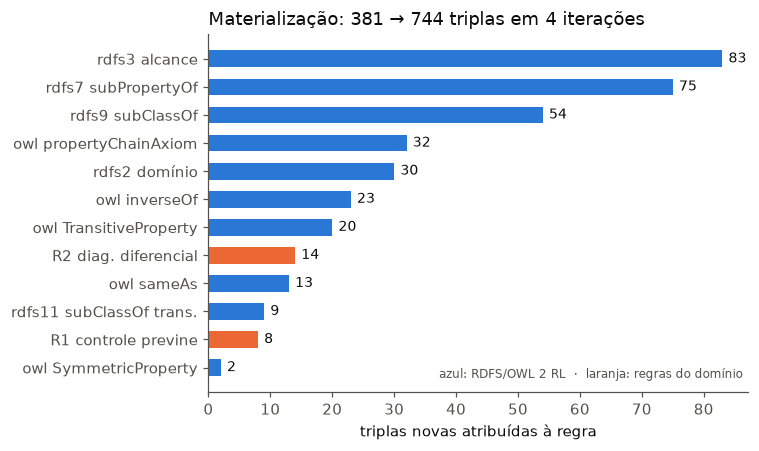

,rdfs3 alcance,rdfs7 subPropertyOf,rdfs9 subClassOf,owl propertyChainAxiom,rdfs2 domínio,owl inverseOf,owl TransitiveProperty,R2 diag. diferencial,owl sameAs,rdfs11 subClassOf trans.,R1 controle previne,owl SymmetricProperty
triplas,83,75,54,32,30,23,20,14,13,9,8,2


In [6]:
por_regra = pd.Series(contagem_por_regra(procedencia)).sort_values()
fig, ax = plt.subplots(figsize=(7, 4.2))
cor = ["#eb6834" if n.startswith("R") else "#2a78d6" for n in por_regra.index]
ax.barh(por_regra.index, por_regra.values, color=cor, height=0.6)
for y, v in enumerate(por_regra.values):
    ax.text(v + 1, y, str(v), va="center", color=TINTA, fontsize=9)
ax.set_xlabel("triplas novas atribuídas à regra")
ax.set_title(f"Materialização: {len(g)} → {len(fecho)} triplas em {len(iteracoes)} iterações",
             loc="left", color=TINTA)
ax.text(0.99, 0.04, "azul: RDFS/OWL 2 RL  ·  laranja: regras do domínio", transform=ax.transAxes,
        ha="right", color=TINTA2, fontsize=8)
fig.tight_layout(); fig.savefig(FIG / "q14_materializacao_por_regra.png"); plt.show()
por_regra.sort_values(ascending=False).rename("triplas").to_frame().T

### 2.1 Conferência com o `owlrl`

Sem as regras R1 e R2, o fecho deveria coincidir com o do pacote `owlrl` (implementação de
referência do OWL 2 RL em Python) no vocabulário do domínio. O `owlrl` também gera triplas
reflexivas (`C subClassOf C`, `x sameAs x`) e axiomas sobre o próprio vocabulário OWL, que
ficam fora da comparação. O mesmo teste roda em `test_q14_inferencia.py`.

In [7]:
try:
    import owlrl
    from rdflib import Graph
    from raciocinio import REGRAS
    so_padrao = {k: v for k, v in REGRAS.items() if not k.startswith("R")}
    meu, _, _ = materializar(g, so_padrao)
    ref = Graph()
    for t in g:
        ref.add(t)
    owlrl.DeductiveClosure(owlrl.OWLRL_Semantics).expand(ref)
    extras = (RDF.type, RDFS.subClassOf, RDFS.subPropertyOf, URIRef("http://www.w3.org/2002/07/owl#sameAs"))
    def dominio(gr):
        return {(s, p, o) for s, p, o in gr if str(s).startswith(str(ARBO)) and isinstance(o, URIRef)
                and str(o).startswith(str(ARBO)) and s != o and "cadeia_" not in str(s)
                and (str(p).startswith(str(ARBO)) or p in extras)}
    a, b = dominio(meu), dominio(ref)
    print(f"owlrl: {len(ref)} triplas no total; no vocabulário arbo: nosso {len(a)}, owlrl {len(b)}, iguais: {a == b}")
except ImportError:
    print("owlrl não instalado; conferência pulada")

owlrl: 1354 triplas no total; no vocabulário arbo: nosso 550, owlrl 550, iguais: True


## 3. Consultas SPARQL antes e depois da inferência

As consultas C1 a C9 são escritas como alguém que conhece só o esquema escreveria. No grafo
assertado quase todas voltam vazias ou incompletas. As versões `_caminho` respondem certo no
grafo assertado porque embutem a regra na própria consulta com *property paths*
(`pertenceATaxon+`, `parteDe*`, `rdf:type/rdfs:subClassOf*`).

In [8]:
linhas = []
for nome in CONSULTAS:
    antes, depois = consultar(g, nome), consultar(fecho, nome)
    linhas.append({"consulta": nome, "n antes": len(antes), "n depois": len(depois),
                   "respostas depois da inferência": ", ".join(depois)})
tab_consultas = pd.DataFrame(linhas)
tab_consultas

,consulta,n antes,n depois,respostas depois da inferência
0,C1 arboviroses,0,7,"Chikungunya, Dengue, Febre amarela, Febre do Mayaro, Febre do Nilo Ocidental, Febre do Oropouche, Zika"
1,C2 vírus da família Flaviviridae,0,4,"DENV (vírus da dengue), WNV (vírus do Nilo Ocidental), YFV (vírus da febre amarela), ZIKV (vírus Zika)"
2,C2_caminho,4,4,"DENV (vírus da dengue), WNV (vírus do Nilo Ocidental), YFV (vírus da febre amarela), ZIKV (vírus Zika)"
3,C3 doenças transmitidas por insetos,0,7,"Chikungunya, Dengue, Febre amarela, Febre do Mayaro, Febre do Nilo Ocidental, Febre do Oropouche, Zika"
4,C3_caminho,7,7,"Chikungunya, Dengue, Febre amarela, Febre do Mayaro, Febre do Nilo Ocidental, Febre do Oropouche, Zika"
5,C4 doenças que ocorrem no Nordeste,2,5,"Chikungunya, Dengue, Febre do Nilo Ocidental, Febre do Oropouche, Zika"
6,C4_caminho,5,5,"Chikungunya, Dengue, Febre do Nilo Ocidental, Febre do Oropouche, Zika"
7,C5 medidas que previnem a febre do Oropouche,0,1,Manejo de matéria orgânica
8,C6 vírus da família Togaviridae,0,2,"CHIKV (vírus chikungunya), MAYV (vírus Mayaro)"
9,C7 diagnóstico diferencial da febre do Mayaro,0,3,"Chikungunya, Dengue, Zika"


In [9]:
for nome in ["C2 vírus da família Flaviviridae", "C3 doenças transmitidas por insetos", "C4 doenças que ocorrem no Nordeste"]:
    print(nome, CONSULTAS[nome])
    print("   versão com property path:", CONSULTAS[nome.split()[0] + "_caminho"], "\n")

C2 vírus da família Flaviviridae 
SELECT ?x WHERE { ?x arbo:pertenceATaxon arbo:Flaviviridae ; a arbo:Virus }
   versão com property path: 
SELECT ?x WHERE { ?x arbo:pertenceATaxon+ arbo:Flaviviridae .
                  ?d arbo:causadaPor ?x } 

C3 doenças transmitidas por insetos 
SELECT DISTINCT ?x WHERE { ?x arbo:transmitidaPor ?v . ?v a arbo:Inseto }
   versão com property path: 
SELECT DISTINCT ?x WHERE {
  ?x arbo:causadaPor/(arbo:vetorPrincipal|arbo:vetorSecundario) ?v .
  ?v a/rdfs:subClassOf* arbo:Inseto } 

C4 doenças que ocorrem no Nordeste 
SELECT ?x WHERE { ?x arbo:ocorreEm arbo:RegiaoNordeste }
   versão com property path: 
SELECT DISTINCT ?x WHERE { ?x arbo:ocorreEm/arbo:parteDe* arbo:RegiaoNordeste } 



A C9 usa `FILTER NOT EXISTS`, ou seja, raciocina em mundo fechado: "não há vacina no grafo".
Sob a semântica de mundo aberto do RDF/OWL isso não autoriza concluir que a vacina não existe,
só que o grafo não sabe. Para Zika, Oropouche, Mayaro e Nilo Ocidental a resposta coincide com
a realidade (não há vacina licenciada para uso humano no Brasil), mas por sorte dos dados, não
por garantia lógica. A Questão 1 discute essa diferença entre OWA e CWA.

### 3.1 Arestas assertadas e inferidas em torno da dengue

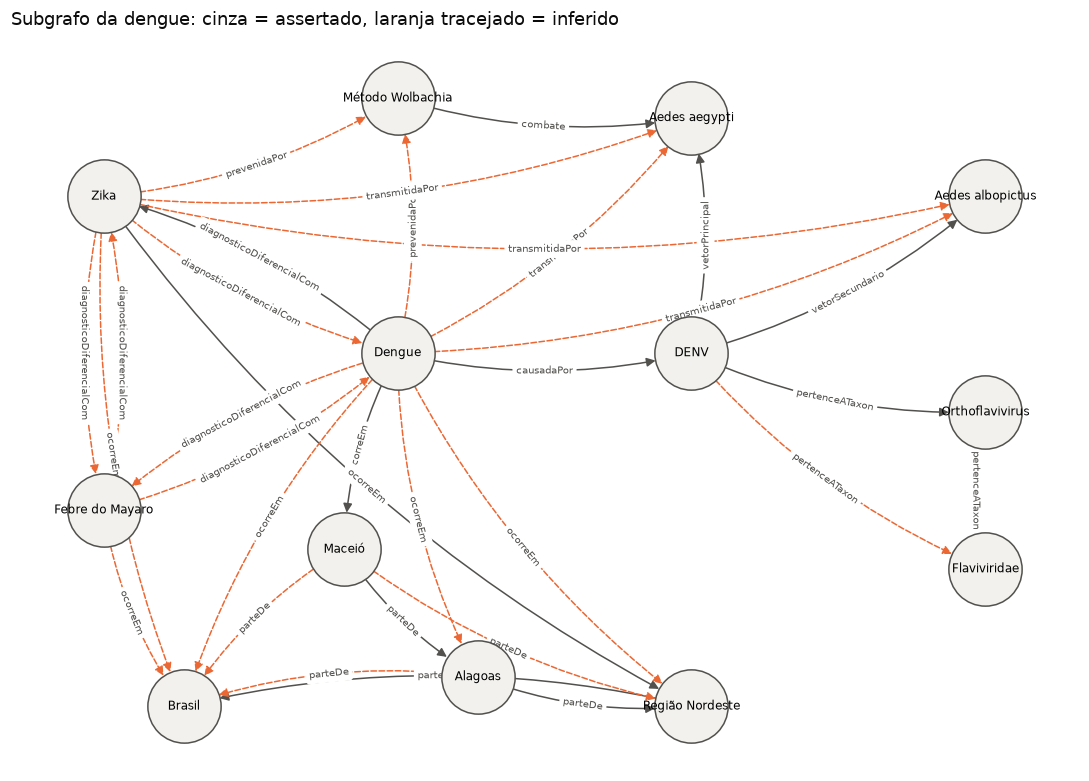

arestas no recorte: 32 (20 inferidas)


In [10]:
mostrar = ["Dengue", "Zika", "FebreMayaro", "DENV", "AedesAegypti", "AedesAlbopictus", "Orthoflavivirus",
           "Flaviviridae", "Maceio", "Alagoas", "RegiaoNordeste", "Brasil", "MetodoWolbachia"]
preds = {"causadaPor", "vetorPrincipal", "vetorSecundario", "transmitidaPor", "pertenceATaxon",
         "ocorreEm", "parteDe", "combate", "prevenidaPor", "diagnosticoDiferencialCom"}
pos = {"Dengue": (0, 0), "Zika": (-2.2, 1.6), "FebreMayaro": (-2.2, -1.6), "DENV": (2.2, 0),
       "AedesAegypti": (2.2, 2.4), "AedesAlbopictus": (4.4, 1.6), "MetodoWolbachia": (0, 2.6),
       "Orthoflavivirus": (4.4, -0.6), "Flaviviridae": (4.4, -2.2), "Maceio": (-0.4, -2.0),
       "Alagoas": (0.6, -3.3), "RegiaoNordeste": (2.2, -3.6), "Brasil": (-1.6, -3.6)}
G = nx.MultiDiGraph()
for s, p, o in fecho:
    s_, p_, o_ = local(s), local(p), local(o)
    if s_ in mostrar and o_ in mostrar and p_ in preds:
        G.add_edge(s_, o_, rel=p_, inferida=(s, p, o) not in g)
fig, ax = plt.subplots(figsize=(10, 7.2))
nx.draw_networkx_nodes(G, pos, node_color="#f2f1ed", edgecolors=TINTA2, node_size=2300, ax=ax)
nx.draw_networkx_labels(G, pos, labels={n: fecho.value(ARBO[n], RDFS.label).split(" (")[0] for n in G},
                        font_size=8, ax=ax)
for inferida, estilo, cor in [(False, "solid", TINTA2), (True, "dashed", "#eb6834")]:
    arestas = [(u, v) for u, v, d in G.edges(data=True) if d["inferida"] == inferida]
    nx.draw_networkx_edges(G, pos, edgelist=arestas, style=estilo, edge_color=cor, node_size=2300,
                           arrowsize=12, connectionstyle="arc3,rad=0.12", ax=ax)
rotulos = {}
for u, v, d in G.edges(data=True):
    rotulos.setdefault((u, v), []).append(d["rel"])
nx.draw_networkx_edge_labels(G, pos, edge_labels={k: "\n".join(v) for k, v in rotulos.items()},
                             font_size=6.5, font_color=TINTA2, connectionstyle="arc3,rad=0.12", ax=ax)
ax.set_title("Subgrafo da dengue: cinza = assertado, laranja tracejado = inferido", loc="left", color=TINTA)
ax.axis("off"); fig.tight_layout(); fig.savefig(FIG / "q14_subgrafo_dengue.png"); plt.show()
print(f"arestas no recorte: {G.number_of_edges()} ({sum(d['inferida'] for *_, d in G.edges(data=True))} inferidas)")

## 4. Aprendizagem: TransE e previsão de links

Protocolo:
- os 156 fatos relacionais assertados são divididos em treino e teste (15%), em 10 sementes;
- triplas de teste cujas entidades não aparecem no treino voltam para o treino;
- cada tripla de teste gera duas consultas, `(h, r, ?)` e `(?, r, t)`, ranqueadas contra as 78
  entidades no modo filtrado (as outras respostas verdadeiras do fecho completo saem da disputa);
- métricas: MRR, Hits@1, Hits@3, Hits@10 e posto médio (MR);
- modelos: aleatório, frequência (a entidade mais comum naquela posição da relação, no treino),
  TransE treinado nos fatos assertados e TransE treinado no fecho do treino (materializado).

O treino materializado é recalculado em cada divisão a partir só das triplas de treino, para
não vazar informação do teste. Se o raciocinador conseguir deduzir uma tripla de teste, ela é
contada à parte e retirada do treino materializado.

### 4.1 Escolha de hiperparâmetros na validação

A grade é pequena e a escolha usa uma validação tirada do treino (sementes 100 a 102), sem
olhar o teste.

In [11]:
ent_nomes = {local(e) for e in ents}
idx = te.Indice(ent_nomes, {r for _, r, _ in fatos_rel_fecho})
conhecidas = idx.ids(fatos_rel_fecho)
grade = []
for dim in [16, 32, 64]:
    for margem in [0.5, 1.0, 2.0]:
        mrr = []
        for seed in [100, 101, 102]:
            treino, _ = te.dividir(fatos_rel, 0.15, seed)
            sub, val = te.dividir(treino, 0.15, seed)
            E, R, _ = te.treinar_transe(idx.ids(sub), len(idx.ent), len(idx.rel), dim=dim, margem=margem,
                                        lr=0.01, epocas=300, seed=seed)
            mrr.append(te.metricas(te.avaliar(idx.ids(val), conhecidas, *te.escores_transe(E, R)))["MRR"])
        grade.append({"dim": dim, "margem": margem, "MRR validação": np.mean(mrr)})
grade = pd.DataFrame(grade)
melhor = grade.loc[grade["MRR validação"].idxmax()]
CFG = dict(dim=int(melhor["dim"]), margem=float(melhor["margem"]), lr=0.01, epocas=300)
print("configuração escolhida:", CFG)
grade.pivot(index="dim", columns="margem", values="MRR validação").round(3)

configuração escolhida: {'dim': 64, 'margem': 1.0, 'lr': 0.01, 'epocas': 300}


margem,0.5,1.0,2.0
dim,,,
16,0.459,0.615,0.582
32,0.478,0.602,0.560
64,0.449,0.637,0.538


### 4.2 Resultados no teste (10 divisões)

In [12]:
linhas, por_relacao = te.experimento(g, range(10), CFG, frac_teste=0.15)
res = pd.DataFrame(linhas)
ordem = ["Aleatório", "Frequência", "TransE (assertado)", "TransE (materializado)"]
resumo = res.groupby("modelo")[["MRR", "Hits@1", "Hits@3", "Hits@10", "MR"]].agg(["mean", "std"]).loc[ordem]
print(f"triplas de teste por divisão: {res['n_teste'].mean():.1f} em média "
      f"({res.groupby('seed')['n_teste'].first().min()} a {res.groupby('seed')['n_teste'].first().max()})")
print(f"treino assertado: {res[res.modelo == 'TransE (assertado)']['n_treino'].mean():.1f} triplas; "
      f"treino materializado: {res[res.modelo == 'TransE (materializado)']['n_treino'].mean():.1f} triplas")
ded = res.groupby("seed")["n_deduzidas"].first()
print(f"triplas de teste recuperadas por dedução a partir do treino: {ded.sum()} em {len(ded)} divisões")
resumo.round(3)

triplas de teste por divisão: 17.4 em média (15 a 21)
treino assertado: 138.6 triplas; treino materializado: 284.9 triplas
triplas de teste recuperadas por dedução a partir do treino: 2 em 10 divisões


MRR        Hits@1        Hits@3        Hits@10  \
                         mean    std   mean    std   mean    std    mean   
modelo                                                                     
Aleatório               0.062  0.014  0.006  0.013  0.043  0.031   0.131   
Frequência              0.506  0.070  0.361  0.074  0.571  0.086   0.688   
TransE (assertado)      0.602  0.040  0.431  0.049  0.700  0.092   0.980   
TransE (materializado)  0.600  0.063  0.407  0.083  0.743  0.086   0.988   

                                   MR         
                          std    mean    std  
modelo                                        
Aleatório               0.033  37.573  2.973  
Frequência              0.090  13.962  3.521  
TransE (assertado)      0.025   3.167  0.595  
TransE (materializado)  0.016   3.132  0.651

In [13]:
# quais triplas de teste o raciocinador recupera sozinho
for seed in range(10):
    _, _, _, deduzidas = te.preparar_divisao(g, seed)
    for d in deduzidas:
        print(f"semente {seed}: {d}")

semente 1: ('Dengue', 'diagnosticoDiferencialCom', 'Zika')


semente 8: ('Dengue', 'diagnosticoDiferencialCom', 'Chikungunya')


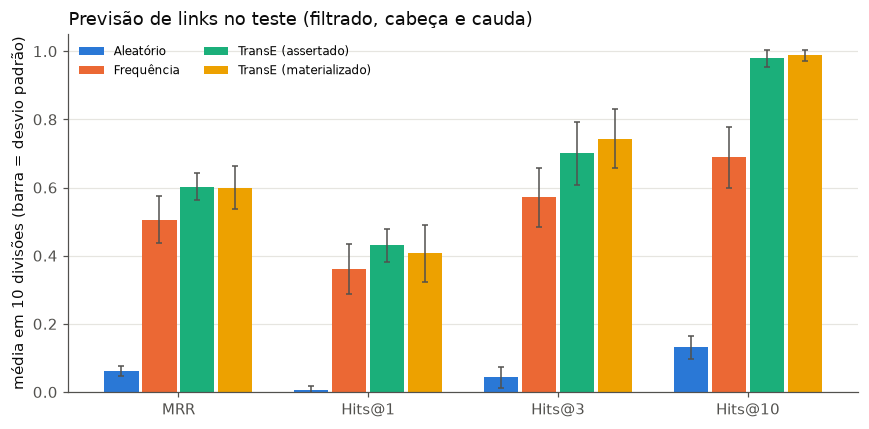

In [14]:
fig, ax = plt.subplots(figsize=(8, 4))
metr = ["MRR", "Hits@1", "Hits@3", "Hits@10"]
larg = 0.2
for i, m in enumerate(ordem):
    medias = [resumo.loc[m, (k, "mean")] for k in metr]
    desvios = [resumo.loc[m, (k, "std")] for k in metr]
    xs = np.arange(len(metr)) + (i - 1.5) * larg
    ax.bar(xs, medias, larg * 0.9, yerr=desvios, color=CORES[i], label=m,
           error_kw=dict(ecolor=TINTA2, lw=1, capsize=2))
ax.set_xticks(np.arange(len(metr)), metr)
ax.set_ylim(0, 1.05); ax.set_ylabel("média em 10 divisões (barra = desvio padrão)")
ax.set_title("Previsão de links no teste (filtrado, cabeça e cauda)", loc="left", color=TINTA)
ax.legend(frameon=False, ncol=2, fontsize=8, loc="upper left")
ax.grid(axis="y", color="#e6e5e0", lw=0.8); ax.set_axisbelow(True)
fig.tight_layout(); fig.savefig(FIG / "q14_transe_metricas.png"); plt.show()

### 4.3 Desempenho por relação (TransE, fatos assertados)

TransE modela cada relação como uma única translação. Relações 1-para-N (uma doença tem vários
sintomas) e N-para-1 (vários vírus num gênero) forçam entidades diferentes a ocupar quase o
mesmo ponto, e relações simétricas exigiriam `r ≈ -r`, isto é, `r ≈ 0`.

In [15]:
tab_rel = pd.DataFrame([{"relação": r, "consultas": len(v), "MRR": np.mean(1 / np.array(v)),
                         "Hits@10": np.mean(np.array(v) <= 10)} for r, v in por_relacao.items()])
tab_rel.sort_values("MRR", ascending=False).round(3).reset_index(drop=True)

,relação,consultas,MRR,Hits@10
0,combate,2,1.000,1.000
1,diagnosticadaPor,30,0.967,1.000
2,diagnosticoDiferencialCom,8,0.875,1.000
3,temSintoma,116,0.767,1.000
4,hospedeiroAmplificador,24,0.684,1.000
5,vetorSecundario,12,0.590,1.000
6,ambiente,8,0.589,0.875
7,podeEvoluirPara,16,0.568,1.000
8,vetorPrincipal,26,0.412,0.885
9,ocorreEm,40,0.404,1.000


### 4.4 Curva de treino e hipóteses do modelo completo

Por fim, o TransE é treinado com todos os fatos do fecho e usado para sugerir triplas que não
estão no grafo. São hipóteses para um especialista conferir, não fatos.

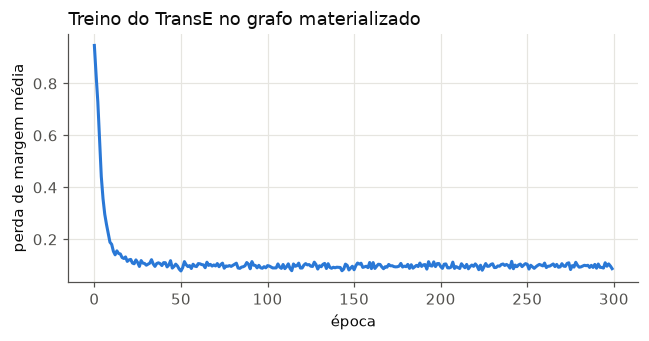

(FebreOropouche, temSintoma, ?)
   já no grafo, no top-10: ['Nausea', 'Febre', 'Cefaleia', 'Mialgia', 'Artralgia', 'Calafrios', 'Fotofobia']
   melhores candidatas novas: ['Exantema', 'Ictericia', 'DorRetroOrbital', 'Prurido', 'EdemaArticular']
(FebreMayaro, vetorSecundario, ?)
   já no grafo, no top-10: []
   melhores candidatas novas: ['Chikungunya', 'Zika', 'AedesAlbopictus', 'Dengue', 'AedesAegypti']
(FebreOropouche, diagnosticadaPor, ?)
   já no grafo, no top-10: ['RTqPCR']
   melhores candidatas novas: ['SorologiaIgM', 'Imunohistoquimica', 'AntigenoNS1', 'PRNT', 'Fotofobia']
(Zika, ocorreEm, ?)
   já no grafo, no top-10: ['Brasil', 'RegiaoNordeste', 'RegiaoSudeste', 'AmericaDoSul']
   melhores candidatas novas: ['Alagoas', 'RegiaoNorte', 'RegiaoCentroOeste', 'Piaui', 'RegiaoSul']


In [16]:
E, R, perdas = te.treinar_transe(idx.ids(fatos_rel_fecho), len(idx.ent), len(idx.rel), seed=0, **CFG)
fig, ax = plt.subplots(figsize=(6, 3.2))
ax.plot(perdas, color=CORES[0], lw=2)
ax.set_xlabel("época"); ax.set_ylabel("perda de margem média")
ax.set_title("Treino do TransE no grafo materializado", loc="left", color=TINTA)
ax.grid(color="#e6e5e0", lw=0.8); ax.set_axisbelow(True)
fig.tight_layout(); fig.savefig(FIG / "q14_transe_perda.png"); plt.show()

caudas, _ = te.escores_transe(E, R)
conhecidas_set = set(fatos_rel_fecho)
def hipoteses(h, r, k=5):
    s = caudas(idx.ent[h], idx.rel[r])
    ordem_ = [idx.nome_ent[i] for i in np.argsort(-s)]
    novas = [t for t in ordem_ if (h, r, t) not in conhecidas_set and t != h][:k]
    conhecidas_ = [t for t in ordem_[:10] if (h, r, t) in conhecidas_set]
    return novas, conhecidas_
for h, r in [("FebreOropouche", "temSintoma"), ("FebreMayaro", "vetorSecundario"),
             ("FebreOropouche", "diagnosticadaPor"), ("Zika", "ocorreEm")]:
    novas, ja = hipoteses(h, r)
    print(f"({h}, {r}, ?)\n   já no grafo, no top-10: {ja}\n   melhores candidatas novas: {novas}")

### 4.5 Projeção 2D dos embeddings

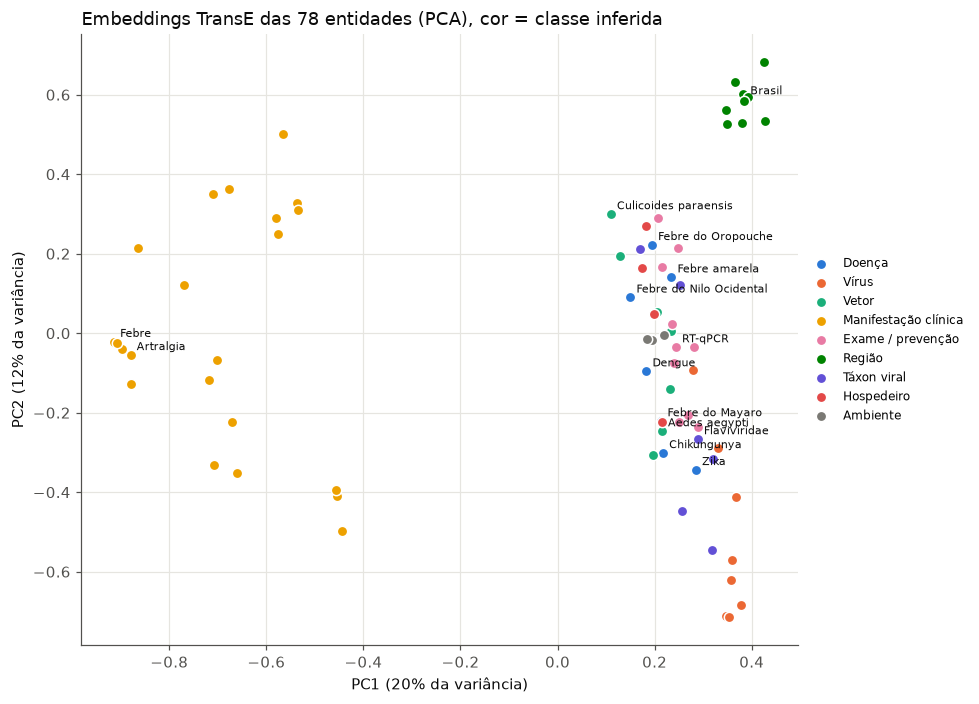

variância explicada pelos 2 componentes: 32% de 64 dimensões


In [17]:
from sklearn.decomposition import PCA
categorias = [("Arbovirose", "Doença"), ("Arbovirus", "Vírus"), ("Vetor", "Vetor"),
              ("ManifestacaoClinica", "Manifestação clínica"), ("Intervencao", "Exame / prevenção"),
              ("Regiao", "Região"), ("TaxonViral", "Táxon viral"), ("Hospedeiro", "Hospedeiro"),
              ("AmbienteDeTransmissao", "Ambiente")]
def categoria(nome):
    tipos = {local(t) for t in fecho.objects(ARBO[nome], RDF.type)}
    return next(rot for cls, rot in categorias if cls in tipos)
cat = [categoria(n) for n in idx.nome_ent]
P = PCA(n_components=2, random_state=0).fit(E)
Z = P.transform(E)
fig, ax = plt.subplots(figsize=(9, 6.5))
for i, (_, rot) in enumerate(categorias):
    m = np.array([c == rot for c in cat])
    ax.scatter(Z[m, 0], Z[m, 1], s=46, color=CORES[i], edgecolor="white", lw=1, label=rot, zorder=3)
destaque = ["Dengue", "Zika", "Chikungunya", "FebreMayaro", "FebreOropouche", "FebreAmarela", "FebreDoNiloOcidental",
            "AedesAegypti", "CulicoidesParaensis", "Febre", "Artralgia", "Brasil", "Flaviviridae", "RTqPCR"]
for n in destaque:
    i = idx.ent[n]
    ax.annotate(fecho.value(ARBO[n], RDFS.label).split(" (")[0], Z[i], xytext=(4, 3),
                textcoords="offset points", fontsize=7.5, color=TINTA)
ax.set_xlabel(f"PC1 ({P.explained_variance_ratio_[0]:.0%} da variância)")
ax.set_ylabel(f"PC2 ({P.explained_variance_ratio_[1]:.0%} da variância)")
ax.set_title("Embeddings TransE das 78 entidades (PCA), cor = classe inferida", loc="left", color=TINTA)
ax.legend(frameon=False, fontsize=8, loc="center left", bbox_to_anchor=(1, 0.5))
ax.grid(color="#e6e5e0", lw=0.8); ax.set_axisbelow(True)
fig.tight_layout(); fig.savefig(FIG / "q14_transe_pca.png"); plt.show()
print(f"variância explicada pelos 2 componentes: {P.explained_variance_ratio_[:2].sum():.0%} de {CFG['dim']} dimensões")

In [18]:
# coerência por classe: distância média ao centróide da própria classe vs. ao das outras
from sklearn.metrics import silhouette_score
print(f"silhueta das classes no espaço completo ({CFG['dim']}D, distância euclidiana): "
      f"{silhouette_score(E, cat):.3f}")

silhueta das classes no espaço completo (64D, distância euclidiana): 0.442


## 5. Neo4j

`neo4j/arboviroses.cypher` é gerado por `exportar_cypher` a partir do grafo assertado, e
`neo4j/consultas.cypher` reescreve as consultas em Cypher. O script `neo4j/validar_neo4j.sh`
sobe um container `neo4j:5.26-community` temporário, roda os dois arquivos e grava
`neo4j/saida_validacao.txt`. A célula abaixo compara aquela saída com as respostas do SPARQL
sobre o grafo materializado.

In [19]:
import json, re
saida = Path("neo4j/saida_validacao.txt")
if saida.exists():
    cypher = {}
    for linha in saida.read_text(encoding="utf-8").splitlines():
        m = re.match(r'^"(C\d)", (\[.*\])$', linha)
        if m:
            cypher[m.group(1)] = sorted(re.sub(r" \(\d+\)$", "", x) for x in json.loads(m.group(2)))
    comparacao = []
    for nome in CONSULTAS:
        cid = nome.split()[0]
        if cid in cypher:
            sparql = consultar(fecho, nome)
            comparacao.append({"consulta": nome, "SPARQL (materializado)": len(sparql),
                               "Cypher (assertado)": len(cypher[cid]), "iguais": sparql == cypher[cid]})
    display(pd.DataFrame(comparacao))
    print(saida.read_text(encoding="utf-8").split("consulta, respostas")[0])
else:
    print("rode neo4j/validar_neo4j.sh para gerar a saída do Neo4j")

,consulta,SPARQL (materializado),Cypher (assertado),iguais
0,C1 arboviroses,7,7,True
1,C2 vírus da família Flaviviridae,4,4,True
2,C3 doenças transmitidas por insetos,7,7,True
3,C4 doenças que ocorrem no Nordeste,5,5,True
4,C5 medidas que previnem a febre do Oropouche,1,1,True
5,C6 vírus da família Togaviridae,2,2,True
6,C7 diagnóstico diferencial da febre do Mayaro,3,3,True
7,C9 arboviroses sem vacina registrada no grafo,4,4,True


# Validação no neo4j:5.26-community em 2026-11-07
entidades, classes, relacoes
78, 29, 206



Na C6, `owl:sameAs` faz `CHIKV` e `VirusChikungunya` herdarem as triplas um do outro, inclusive
os rótulos. As duas IRIs passam a responder à consulta, mas com o mesmo menor rótulo, e a
resposta aparece uma vez só. No Cypher a identidade é uma aresta `:MESMO_QUE` que a consulta
atravessa, e o resultado é o mesmo. Na C7, o Cypher calcula a regra R2 na hora (Mayaro divide
5 sintomas com a dengue e 6 com Zika e chikungunya); o SPARQL lê o resultado materializado.